# diffusion GRPO 简化实现

把 [05 篇 diffusion RL](../notes/04_RL/04_05_diffusionRL.md) 写成能跑的代码，本地 CPU 几秒跑完。

那篇的主线是：GRPO 的 loop 整套搬过来，只换了模型每步产出什么——下一个 token 变成去噪一步。这里挑能在 CPU 上落实的结论验一遍：

**玩具设定**：latent 2 维（真实是 `[16,64,64]` 共 65536 个元素），"DiT" 是两层 MLP，reward = 离目标点多近。

| 节 | 验什么 | 怎么验 |
|---|---|---|
| 2 | 这套 loop 真能训 | reward 从 −8 涨到 −0.03，出图分布迁到目标点 |
| 3 | 取平均把 ratio 的量级压到哪 | 扫几档权重扰动，assert `ρ_sum = ρ_mean ** D` |
| 3 | 为什么必须用 SDE 采样 | 直接算：随机项为 0 时 logprob = nan |
| 4 | 梯度和优化器状态只跟被训参数走 | 全参 vs 只训 LoRA，数元素个数 |
| 4 | ref 不另占一份权重 | 关掉 LoRA 前后比底座的内存地址 |

**没验的**：显存和耗时的绝对值（要 GPU）、训推不一致的修正（要推理、训练两套引擎）。

## 0. 准备

In [1]:
!apt-get -y install fonts-wqy-zenhei

import math, torch, torch.nn as nn
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["WenQuanYi Zen Hei", "Heiti TC", "PingFang SC"]
plt.rcParams["axes.unicode_minus"] = False
torch.manual_seed(0)

N_STEPS = 10                                       # 去噪步数，正文 demo 也是 10
SIGMAS  = torch.linspace(0.98, 0.02, N_STEPS + 1)  # 两端都不取到 0/1：σ=1 时 σ/(1-σ) 发散，σ=0 时 std=0
TARGET  = torch.tensor([2.0, 2.0])                 # reward 的目标点
G       = 16                                       # 组内条数，正文 demo 也是 16

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-wqy-zenhei
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 7,472 kB of archives.
After this operation, 16.8 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-wqy-zenhei all 0.9.45-8 [7,472 kB]
Fetched 7,472 kB in 1s (13.3 MB/s)
Selecting previously unselected package fonts-wqy-zenhei.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-wqy-zenhei_0.9.45-8_all.deb ...
Unpacking fonts-wqy-zenhei (0.9.45-8) ...
Setting up fonts-wqy-zenhei (0.9.45-8) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


## 1. 一步去噪与 logprob ｜ 正文 §2.3

一步去噪分两件事：**瞄准**（预测速度，沿它走到 μ）和**偏一点**（加一份噪声，落到 x_prev）。
logprob 就是实际落点在这个高斯上的高度——落得离瞄准点越近，值越大。

In [2]:
def sde_step(v, x, sigma, sigma_next, noise_level=0.7):
    """SDE 采样走一步

    参数:
    - v: 预测的速度 (B, D)；x: 当前 latent (B, D)
    - sigma, sigma_next: 这一步起止的噪声水平，标量
    - noise_level: 随机项幅度；0 则退化成 ODE（确定性，没有 logprob）

    返回: x_prev (B, D)、mu (B, D)、noise_std 标量
    公式同 miles_diffusion 的 FlowSdeStepBackend，省掉了 σ≈1 处的 sigma_max 替换
    """
    dt  = sigma_next - sigma                        # 负数，时钟往 0 走
    std_dev_t = (sigma / (1 - sigma)).sqrt() * noise_level          # 扩散尺度，KL 的分母
    mu  = (x * (1 + std_dev_t ** 2 / (2 * sigma) * dt)              # 瞄准点：ODE 的一步
           + v * (1 + std_dev_t ** 2 * (1 - sigma) / (2 * sigma)) * dt)   # 加 SDE 的漂移修正
    noise_std = std_dev_t * (-dt).sqrt()            # 本步随机项幅度，logprob 用的是它
    return mu + noise_std * torch.randn_like(mu), mu, noise_std


def log_prob(x_prev, mu, std, reduce="mean"):
    """高斯对数密度，对非 batch 维聚合 → (B,)

    reduce="mean" 是框架的做法；"sum" 只在第 3 节做对照
    """
    ll = (-((x_prev - mu) ** 2) / (2 * std ** 2)
          - torch.log(std) - 0.5 * math.log(2 * math.pi))
    return ll.mean(-1) if reduce == "mean" else ll.sum(-1)


# 公式本身对不对：和标准库对一下就够
_mu, _std = torch.randn(4, 8), torch.tensor(0.3)
_x = _mu + _std * torch.randn_like(_mu)
assert torch.allclose(log_prob(_x, _mu, _std, "sum"),
                      torch.distributions.Normal(_mu, _std).log_prob(_x).sum(-1), atol=1e-5)
print("logprob 公式和 torch.distributions 一致")

logprob 公式和 torch.distributions 一致


## 2. 完整 loop：rollout → 打分 → 归一 → update

一条轨迹去噪 10 步，每一步都是一条训练样本；同一组 16 条算 advantage。

`grpo_step` 里算 `surr` 的那两行就是 LLM 的 GRPO，一字没改——换掉的只是喂给它的 logprob 怎么来。

In [3]:
class ToyDiT(nn.Module):
    """两层 MLP 冒充 DiT：输入 (x, sigma) 预测速度 v"""
    def __init__(self, d_hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, d_hidden), nn.Tanh(), nn.Linear(d_hidden, 2))
    def forward(self, x, sigma):
        return self.net(torch.cat([x, sigma.expand(x.shape[0], 1)], -1))


def reward(x0):
    """出图后打分，对应 HPS：离目标越近分越高 → (B,)"""
    return -((x0 - TARGET) ** 2).sum(-1)


@torch.no_grad()
def rollout(dit, n=G):
    """从纯噪声去噪，每一步都记下来

    返回: traj（长度 N_STEPS，每项 (x_t, x_prev, old_logp)）、最终 latent (n, 2)
    """
    x, traj = torch.randn(n, 2) * SIGMAS[0], []
    for i in range(N_STEPS):
        v = dit(x, SIGMAS[i])                              # 每步整段前向，没有 KV cache
        xp, mu, std = sde_step(v, x, SIGMAS[i], SIGMAS[i + 1])
        traj.append((x, xp, log_prob(xp, mu, std)))        # old_logp 当场记下（bypass）
        x = xp                                             # 下一步输入全变，没什么可复用
    return traj, x

In [4]:
def grpo_step(dit, opt, eps=1e-4):
    """一个 step，返回这步的平均 reward"""
    traj, x0 = rollout(dit)
    R = reward(x0)
    A = (R - R.mean()) / (R.std() + 1e-4)                  # 组内归一，一条轨迹的 10 步共用

    losses = []
    for i, (x_t, x_prev, old_logp) in enumerate(traj):     # 一步 = 一条训练样本
        v = dit(x_t, SIGMAS[i])                            # actor，带梯度，每步一次
        _, mu, std = sde_step(v, x_t, SIGMAS[i], SIGMAS[i + 1])
        ratio = (log_prob(x_prev, mu, std) - old_logp).exp()        # 分母来自 rollout
        losses.append(-torch.min(ratio * A, ratio.clamp(1-eps, 1+eps) * A))   # 同 LLM
    loss = torch.stack(losses).mean()

    opt.zero_grad(); loss.backward(); opt.step()
    return R.mean().item()


dit = ToyDiT()
opt = torch.optim.Adam(dit.parameters(), lr=3e-2)   # 玩具值；recipe 用 3e-4

_, x_before = rollout(dit, 200)
hist = [grpo_step(dit, opt) for _ in range(300)]
_, x_after  = rollout(dit, 200)
print(f"平均 reward: {hist[0]:.2f} → {sum(hist[-20:])/20:.2f}")

平均 reward: -8.24 → -0.03


/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/767394573.py:8: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_23981/7673945

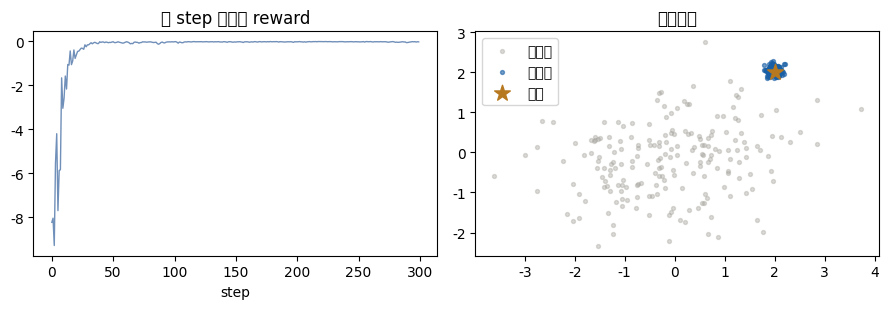

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(hist, color="#708FB9", lw=1)
ax[0].set_title("每 step 的平均 reward"); ax[0].set_xlabel("step")
ax[1].scatter(*x_before.T, s=8, alpha=.4, color="#A5A49D", label="训练前")
ax[1].scatter(*x_after.T,  s=8, alpha=.6, color="#195FA5", label="训练后")
ax[1].scatter(*TARGET, s=140, marker="*", color="#B7791F", label="目标", zorder=3)
ax[1].set_title("出图分布"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. logprob 的两个前提

上面 `log_prob` 里有两处选择，各自决定一件事。

**一、对 65536 个元素取平均，不是求和。** 于是 logprob 的量级回到"单个元素"，ratio 偏离 1 的幅度小了 D 倍——clip 半径因此从 LLM 的 0.2 换到 1e-4。

In [6]:
D   = 4096                                         # 玩具维度；真实是 65536
std = torch.tensor(0.5)
mu_old = torch.randn(64, D)
x_prev = mu_old + std * torch.randn_like(mu_old)   # rollout 实际走到的点

print(f"{'权重扰动':>8} | {'ρ (mean 口径)':>16} | {'ρ (sum 口径)':>14}")
for delta in [1e-4, 1e-3, 1e-2]:                   # 扰动多大未知，所以扫几档看关系
    mu_new = mu_old + delta * torch.randn_like(mu_old)
    rm = (log_prob(x_prev, mu_new, std, "mean") - log_prob(x_prev, mu_old, std, "mean")).exp()
    rs = (log_prob(x_prev, mu_new, std, "sum")  - log_prob(x_prev, mu_old, std, "sum")).exp()
    print(f"{delta:>8.0e} | {rm.median():>16.8f} | {rs.median():>14.4g}")

# 关系本身是恒等的，和扰动多大无关
mu_new = mu_old + 1e-3 * torch.randn_like(mu_old)
rm = (log_prob(x_prev, mu_new, std, "mean") - log_prob(x_prev, mu_old, std, "mean")).exp()
rs = (log_prob(x_prev, mu_new, std, "sum")  - log_prob(x_prev, mu_old, std, "sum")).exp()
assert torch.allclose(rs, rm ** D, rtol=1e-3)
print()
print(f"恒等关系：ρ_sum = ρ_mean ** {D}（已 assert）")
print("所以 clip 半径必须按 mean 口径定，比 LLM 的 0.2 小几个数量级；具体取 1e-4 是 recipe 的配置，不是算出来的")

    权重扰动 |      ρ (mean 口径) |     ρ (sum 口径)
   1e-04 |       0.99999946 |         0.9978
   1e-03 |       1.00000000 |              1
   1e-02 |       0.99984998 |         0.5409

恒等关系：ρ_sum = ρ_mean ** 4096（已 assert）
所以 clip 半径必须按 mean 口径定，比 LLM 的 0.2 小几个数量级；具体取 1e-4 是 recipe 的配置，不是算出来的


In [7]:
# 二、必须有随机项。取 0 就退化成 ODE：落点恒等于瞄准点，分布塌成一个点
x, v = torch.randn(64, 16), torch.randn(64, 16) * 0.1

for name, nl in [("ODE", 0.0), ("SDE", 0.7)]:
    xp, mu, std = sde_step(v, x, SIGMAS[3], SIGMAS[4], noise_level=nl)
    gap = (xp - mu).abs().max()                    # 落点离瞄准点多远
    lp  = log_prob(xp, mu, std)                    # 直接算，不做特判
    print(f"{name}: std = {std.item():.4f} | 落点与瞄准点最大差 = {gap:.2e} | logprob = {lp[0].item()}")

print()
print("ODE 下随机项为 0，落点恒等于瞄准点，分布退化成一个点：std=0 让密度公式除零，logprob 没有定义。")
print("没有 logprob 就没有 ratio，梯度里也就没有「这一步走得好不好」的信号——Flow-GRPO 因此改走 SDE。")

ODE: std = 0.0000 | 落点与瞄准点最大差 = 0.00e+00 | logprob = nan
SDE: std = 0.3251 | 落点与瞄准点最大差 = 1.08e+00 | logprob = -0.2545861601829529

ODE 下随机项为 0，落点恒等于瞄准点，分布退化成一个点：std=0 让密度公式除零，logprob 没有定义。
没有 logprob 就没有 ratio，梯度里也就没有「这一步走得好不好」的信号——Flow-GRPO 因此改走 SDE。


## 4. 显存：结构能验，绝对值不能 ｜ 正文 §3.1

正文那些 GB 是按参数量估的，没有 GPU 也没法实测。但 §3.1 真正的结论是结构性的，这两条可以直接数出来：

- **训练态（梯度 + 优化器状态）只跟被训参数走**，不跟底座走
- **ref 不另占一份权重**：关掉 LoRA 的 actor 就是 ref，底座是同一块内存

In [8]:
class LoRALinear(nn.Module):
    """给一个冻结的 Linear 挂上 LoRA；disable() 时前向等价于原始底座"""
    def __init__(self, base, rank=4):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)                        # 底座冻结
        self.A = nn.Parameter(torch.randn(rank, base.in_features) * 0.01)
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        self.on = True
    def forward(self, x):
        out = self.base(x)
        return out + (x @ self.A.T) @ self.B.T if self.on else out


def train_state_size(model, opt):
    """数训练态：梯度 + 优化器状态的元素个数"""
    grad = sum(p.grad.numel() for p in model.parameters() if p.grad is not None)
    state = sum(v.numel() for s in opt.state.values() for v in s.values() if torch.is_tensor(v))
    # Adam 每个参数存 exp_avg + exp_avg_sq，外加一个 step 计数器（所以总数比 2 倍多一点）
    return grad, state

In [9]:
base_dim = 512
def build(lora):
    net = nn.Linear(base_dim, base_dim)
    m   = LoRALinear(net) if lora else net
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-3)
    m(torch.randn(8, base_dim)).sum().backward(); opt.step()        # 跑一步才有优化器状态
    return m, opt

for name, lora in [("全参训练", False), ("只训 LoRA", True)]:
    m, opt = build(lora)
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in m.parameters())
    g, st = train_state_size(m, opt)
    print(f"{name:9s} 总参数 {total:7d} | 其中被训 {trainable:6d} | 梯度 {g:6d} | 优化器状态 {st:6d}")

print()
print("梯度和优化器状态都只正比于「被训参数」，底座多大都一样——这就是 §3.1 的 427 GB vs 几十 MB")

全参训练      总参数  262656 | 其中被训 262656 | 梯度 262656 | 优化器状态 525314
只训 LoRA   总参数  266752 | 其中被训   4096 | 梯度   4096 | 优化器状态   8194

梯度和优化器状态都只正比于「被训参数」，底座多大都一样——这就是 §3.1 的 427 GB vs 几十 MB


In [10]:
m, _ = build(lora=True)
x   = torch.randn(4, base_dim)
ptr = m.base.weight.data_ptr()                     # 切换前，底座这块内存的地址

m.on = True;  out_actor = m(x)                     # actor：底座 + LoRA
m.on = False; out_ref   = m(x)                     # ref：同一个模块，关掉 LoRA
m.on = True

print("切换后底座还是同一块内存:", m.base.weight.data_ptr() == ptr)
print("两次输出不同，说明 LoRA 真的在起作用:", not torch.allclose(out_actor, out_ref))
print("参数表里只有一份底座 + 一组 LoRA:", [n for n, _ in m.named_parameters()])
print("→ 要 ref 的输出只是再前向一次，没有第二份权重（对比 LLM 侧的 ref 61 GB）")

切换后底座还是同一块内存: True
两次输出不同，说明 LoRA 真的在起作用: True
参数表里只有一份底座 + 一组 LoRA: ['A', 'B', 'base.weight', 'base.bias']
→ 要 ref 的输出只是再前向一次，没有第二份权重（对比 LLM 侧的 ref 61 GB）


## 小结

- **loop 整套搬过来**：`grpo_step` 里算 `surr` 那两行就是 LLM 的 GRPO，换的只是模型每步产出什么
- **logprob 的两个前提**：取平均把 ratio 压到 1e-4 量级，clip 跟着变；没有随机项就没有 logprob
- **训练态只跟被训参数走**：底座多大都不影响梯度和优化器状态，ref 复用同一块底座

没验的：绝对显存和耗时（要 GPU）、CFG 两支、训推不一致的修正（§2.5，那需要两套引擎）。